# 3. Regressão: Boston Housing

506 bairros, 13 atributos, prever o valor das casas. Saída linear, MSE e métrica $R^2$.

In [1]:
import sys
sys.path.append("..")  # so we can import the code in src/

import numpy as np

from src.datasets import load_boston, train_val_split, standardize
from src.nn import MLP
from src.optim import Adam
from src.training import train
from src.plots import plot_loss, plot_metric, plot_histograms

PLOTS = "../assets/plots/"

## Dados

Atributos e alvo padronizados com as estatísticas do treino ($R^2$ não muda com isso).

In [2]:
X, y = load_boston()
X_train, y_train, X_val, y_val = train_val_split(X, y, val_fraction=0.2, seed=0)
X_train, X_val = standardize(X_train, X_val)
y_train, y_val = standardize(y_train, y_val)

print("train:", X_train.shape, y_train.shape)
print("val:  ", X_val.shape, y_val.shape)

train: (405, 13) (405, 1)
val:   (101, 13) (101, 1)


## Modelo e treino

In [3]:
model = MLP(input_size=13, hidden_sizes=[32, 16], output_size=1,
            hidden_activation="relu", output_activation="linear", init="he")

optimizer = Adam(model.parameters(), lr=0.001)

history = train(model, optimizer, "mse", X_train, y_train, X_val, y_val,
                epochs=200, batch_size=32, metric_name="r2", print_every=20)

epoch    1 | train loss 1.3644 | val loss 1.4315 | train r2 -0.3644 | val r2 -0.3581
epoch   20 | train loss 0.1811 | val loss 0.1656 | train r2 0.8189 | val r2 0.8429
epoch   40 | train loss 0.1189 | val loss 0.1255 | train r2 0.8811 | val r2 0.8809
epoch   60 | train loss 0.0859 | val loss 0.1098 | train r2 0.9141 | val r2 0.8959
epoch   80 | train loss 0.0699 | val loss 0.0975 | train r2 0.9301 | val r2 0.9075
epoch  100 | train loss 0.0580 | val loss 0.0951 | train r2 0.9420 | val r2 0.9098
epoch  120 | train loss 0.0515 | val loss 0.0948 | train r2 0.9485 | val r2 0.9101


epoch  140 | train loss 0.0467 | val loss 0.0908 | train r2 0.9533 | val r2 0.9139
epoch  160 | train loss 0.0408 | val loss 0.0913 | train r2 0.9592 | val r2 0.9134
epoch  180 | train loss 0.0373 | val loss 0.0905 | train r2 0.9627 | val r2 0.9141
epoch  200 | train loss 0.0330 | val loss 0.0924 | train r2 0.9670 | val r2 0.9123


## Monitoramento

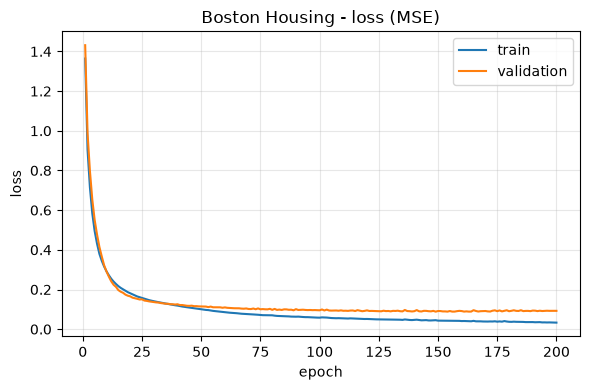

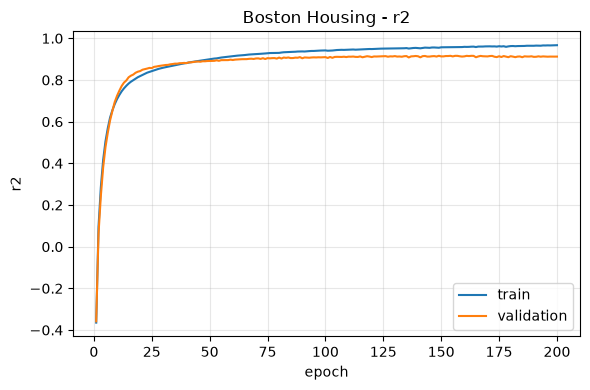

In [4]:
plot_loss(history, title="Boston Housing - loss (MSE)", save_path=PLOTS + "boston_loss.png")
plot_metric(history, "r2", title="Boston Housing - r2", save_path=PLOTS + "boston_r2.png")

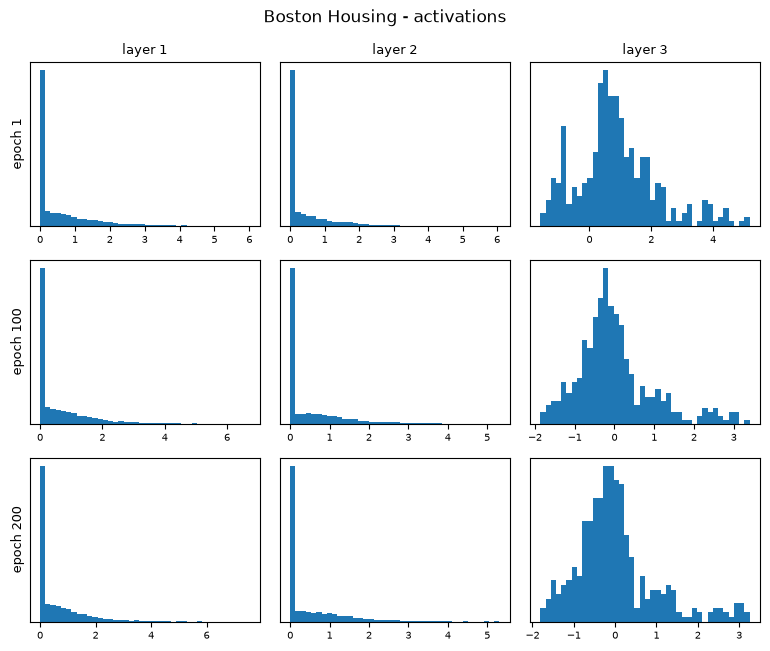

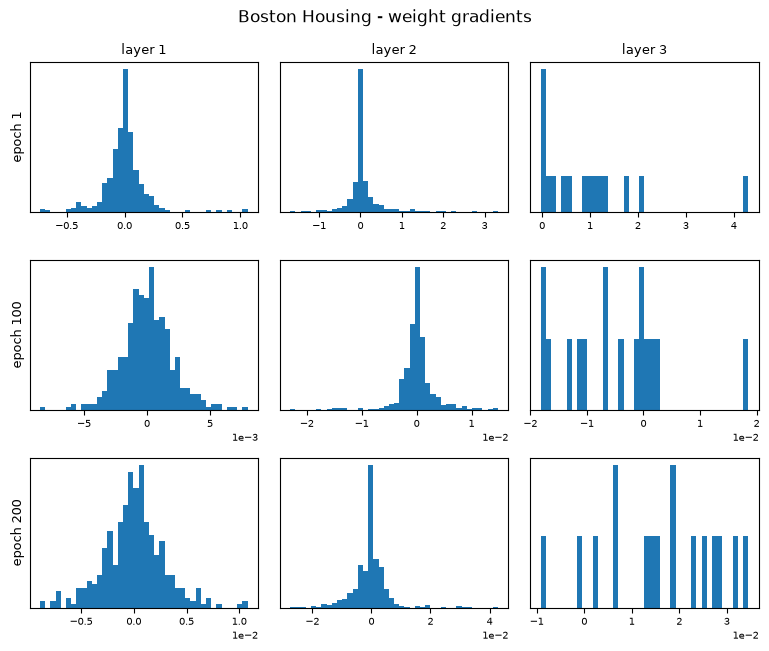

In [5]:
plot_histograms(history, "activations", title="Boston Housing - activations", save_path=PLOTS + "boston_activations.png")
plot_histograms(history, "gradients", title="Boston Housing - weight gradients", save_path=PLOTS + "boston_gradients.png")

## Exportar e importar

In [6]:
model.save("../models/boston_mlp.npz")

loaded_model = MLP.load("../models/boston_mlp.npz")
difference = np.abs(loaded_model.predict(X_val) - model.predict(X_val)).max()
print("largest difference between original and loaded predictions:", difference)

largest difference between original and loaded predictions: 0.0
